#  <center>Exploratory Data Analysis of game balance between races in Starcraft 2

## <Center>What is Starcraft 2?

<Center><img src="sc2.avif">


StarCraft 2 is a real-time strategy game developed and published by Blizzard Entertainment which came out on the 27th of July 2010.
It is the sequel to their original game StarCraft that was released in 1998. 

The gameplay involves the player selecting 1 of 3 factions, The Terrans, Protoss or Zerg to gather resources, construct a base and create an army to complete objectives or eliminate an enemy.

### Aims and Objectives :

The aim of this research is to see how balanced the win rates are between the 3 factions across the whole competetive scene from season 48 - 60 (19 July 2021 - 10 November 2024 )


Aquiring and using Dataset :

I will be obtaining the data from nonapa.com which is a community run website that utilizes the official StarCraft 2 game data API directly from Blizzard.

With this data I will be using graphs to observe possible disparities between the different races at different points throughout the last few years of the game's lifespan

#### JULIAN: Your aims can be more specific. Please see if the below correct and revise thm

### Aims and Objectives :

The aim of this research is to see how balanced the win rates are between the 3 factions across the whole competetive scene from season 48 - 60 (19 July 2021 - 10 November 2024 ). Specifically, my objectives are fourfold: 


**1. Identify and Analyze Regional Disparities in Win Rates**  
**2. Investigate Seasonal Trends and Anomalies**  
**3. Assess the Impact of Skill Levels on Race Balance**  
**4. Explore the Relationship Between Unit Design and Win Rates** 

#### JULIAN: Tell them why these are important to focus









































### Summary of Area of Research : 

This data analysis project is focused on observing the win rates between different factions across all combined skill groups to determine how balanced they are against each other at different points


### Imports

In [1]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup
import urllib3

# Suppress only the single InsecureRequestWarning from urllib3 needed
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

### Relevancy of data and justification for using it
Nonapa.com is one of the best sources for any StarCraft 2 seasonal data as they get the data directly from the APIs that Blizzard themselves have provided. It is also a great middle ground of accessing the APIs as they regularly update and extract the most important information for statistics and analysis.

### Ethics of use of data

The data scrapped comes from a community project that uses the official Blizzard API
https://nonapa.com
The Blizzard API use terms and conditions as well as guides for using them are found on their website
https://develop.battle.net/documentation/guides
https://www.blizzard.com/en-us/legal/a2989b50-5f16-43b1-abec-2ae17cc09dd6/blizzard-developer-api-terms-of-use


### Project Background

#### Why is this field of interest to me?
I have chosen this topic for my research as I grew up playing Blizzard games since I was young. I've also been getting back into the game recently, both as a player and an avid viewer. The main inspiration sparked from watching professional players and the discourse within the community about game balance as there have been no 1st place Protoss winners in the premier competitions and only 1 in the majors this year.

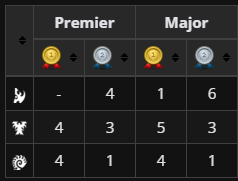

Because of this, I became curious on wether or not this unbalance mainly appears in the most highest of skill levels or throught players of all skill disparities.

### Scope of work
I will mainly be focusing on the spread of win rates between the different races through all skill levels over the last few years. As much as I would like to delve deeper and see what other factors could be closely correlated to the win rates, that data is not easily accessed in terms of both time and effort.

#### JULIAN: Please consider what the specific scopes are. OK?

### Data Processing and analysis pipeline

1. Scrape the data from nonapa.com tables
2. Organize the data into a dataframe
3. Conduct initial data inspection and management should there be a need to.
4. Plot charts and graphs for data visualization.
5. Create conclusions based on data analysis and state of the game at the time

In [2]:
Percentages = []
Seasons = []
# Range 48 - 61 to get data from seasons 48-60
for seasonID in range(48,61):
        Seasons.append(seasonID)
        nonapa_url = f"https://nonapa.com/balance?season={seasonID}&rank=-1&map=all"
        response = requests.get(nonapa_url,verify=False)
        if response.status_code == 200:
            soup = BeautifulSoup(response.content, 'html.parser')
            # Remove span tags as there is a vs between the 2 percentages we need
            for catch in soup.find_all("span"):
                catch.decompose()  

            # Counter to prevent adding race win percentages when random race is selected          
            i = 0
            Append = True
            for dd in soup.find_all("dd", {"class":"text-center col-6 m-0 p-0"}):    
                # Using regex to get each individual percentage to add to array instead of in pairs  
                for percentage in re.findall(r'-?\d*\.?\d+m?', str(dd.text)):            
                    if Append == True:
                        # Put all win percentages into array to put into dataframe later
                        Percentages.append(float(percentage))
                    if i == 5 or i == 17 or i == 29:
                            Append = False
                    if i == 11 or i == 23:
                            Append = True
                    i = i + 1                 
            print(f"Got data for season {seasonID}")       
        else:
            print(f"Failed to retrieve the page. Status code: {response.status_code}")
print(Percentages)

Got data for season 48
Got data for season 49
Got data for season 50
Got data for season 51
Got data for season 52
Got data for season 53
Got data for season 54
Got data for season 55
Got data for season 56
Got data for season 57
Got data for season 58
Got data for season 59
Got data for season 60
[49.34, 50.66, 51.49, 48.51, 52.92, 47.08, 48.72, 51.28, 50.74, 49.26, 53.02, 46.98, 49.76, 50.24, 51.13, 48.87, 53.01, 46.99, 49.18, 50.82, 50.61, 49.39, 53.4, 46.6, 48.45, 51.55, 50.93, 49.07, 52.09, 47.91, 48.54, 51.46, 51.79, 48.21, 53.45, 46.55, 49.29, 50.71, 51.35, 48.65, 53.52, 46.48, 49.02, 50.98, 49.75, 50.25, 52.73, 47.27, 48.88, 51.12, 51.66, 48.34, 53.39, 46.61, 49.05, 50.95, 51.78, 48.22, 52.92, 47.08, 50.21, 49.79, 51.73, 48.27, 52.4, 47.6, 49.18, 50.82, 51.63, 48.37, 53.68, 46.32, 50.07, 49.93, 52.13, 47.87, 52.98, 47.02, 50.94, 49.06, 50.91, 49.09, 52.08, 47.92, 49.71, 50.29, 51.59, 48.41, 52.96, 47.04, 49.65, 50.35, 51.96, 48.04, 52.72, 47.28, 50.59, 49.41, 52.31, 47.69, 52.2

Create pandas Dataframe and save the data to csv in case of any disruption

In [3]:
# Convert python list into np array for reshaping
TableValues = np.array(Percentages)

# Convert 1D array into 2D array so it can be turned into pandas dataframe
TableValues = TableValues.reshape(13,18)
columns=["EU_TVZ", "EU_ZVT", "EU_ZVP", "EU_PVZ", "EU_PVT", "EU_TVP", "KR_TVZ", "KR_ZVT", "KR_ZVP", "KR_PVZ", "KR_PVT", "KR_TVP", "NA_TVZ", "NA_ZVT", "NA_ZVP", "NA_PVZ", "NA_PVT", "NA_TVP"]
WinRates = pd.DataFrame(TableValues, columns=columns, index=Seasons)
WinRates.to_csv("WinRates.csv", index=False)

In [4]:
WinRates

,EU_TVZ,EU_ZVT,EU_ZVP,EU_PVZ,EU_PVT,EU_TVP,KR_TVZ,KR_ZVT,KR_ZVP,KR_PVZ,KR_PVT,KR_TVP,NA_TVZ,NA_ZVT,NA_ZVP,NA_PVZ,NA_PVT,NA_TVP
48,49.34,50.66,51.49,48.51,52.92,47.08,48.72,51.28,50.74,49.26,53.02,46.98,49.76,50.24,51.13,48.87,53.01,46.99
49,49.18,50.82,50.61,49.39,53.40,46.60,48.45,51.55,50.93,49.07,52.09,47.91,48.54,51.46,51.79,48.21,53.45,46.55
50,49.29,50.71,51.35,48.65,53.52,46.48,49.02,50.98,49.75,50.25,52.73,47.27,48.88,51.12,51.66,48.34,53.39,46.61
51,49.05,50.95,51.78,48.22,52.92,47.08,50.21,49.79,51.73,48.27,52.40,47.60,49.18,50.82,51.63,48.37,53.68,46.32
52,50.07,49.93,52.13,47.87,52.98,47.02,50.94,49.06,50.91,49.09,52.08,47.92,49.71,50.29,51.59,48.41,52.96,47.04
53,49.65,50.35,51.96,48.04,52.72,47.28,50.59,49.41,52.31,47.69,52.24,47.76,49.42,50.58,51.61,48.39,52.65,47.35
54,49.26,50.74,51.28,48.72,52.56,47.44,48.89,51.11,51.31,48.69,52.26,47.74,49.60,50.40,51.73,48.27,53.22,46.78
55,49.51,50.49,52.05,47.95,52.71,47.29,49.72,50.28,51.02,48.98,52.65,47.35,49.60,50.40,51.33,48.67,53.19,46.81
56,49.40,50.60,51.29,48.71,52.97,47.03,49.63,50.37,50.97,49.03,52.03,47.97,49.32,50.68,51.50,48.50,53.18,46.82
57,49.59,50.41,51.52,48.48,53.18,46.82,49.59,50.41,51.82,48.18,52.60,47.40,49.72,50.28,51.89,48.11,53.18,46.82


In [5]:
WinRates.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13 entries, 48 to 60
Data columns (total 18 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   EU_TVZ  13 non-null     float64
 1   EU_ZVT  13 non-null     float64
 2   EU_ZVP  13 non-null     float64
 3   EU_PVZ  13 non-null     float64
 4   EU_PVT  13 non-null     float64
 5   EU_TVP  13 non-null     float64
 6   KR_TVZ  13 non-null     float64
 7   KR_ZVT  13 non-null     float64
 8   KR_ZVP  13 non-null     float64
 9   KR_PVZ  13 non-null     float64
 10  KR_PVT  13 non-null     float64
 11  KR_TVP  13 non-null     float64
 12  NA_TVZ  13 non-null     float64
 13  NA_ZVT  13 non-null     float64
 14  NA_ZVP  13 non-null     float64
 15  NA_PVZ  13 non-null     float64
 16  NA_PVT  13 non-null     float64
 17  NA_TVP  13 non-null     float64
dtypes: float64(18)
memory usage: 1.9 KB


Since the data scrapped was only percentages, there is not much work needed for clean up. It also comes from an official source with oversight from the community.

In [6]:
WinRates.mean()

EU_TVZ    49.490000
EU_ZVT    50.510000
EU_ZVP    51.495385
EU_PVZ    48.504615
EU_PVT    53.034615
EU_TVP    46.965385
KR_TVZ    49.537692
KR_ZVT    50.462308
KR_ZVP    51.034615
KR_PVZ    48.965385
KR_PVT    52.386923
KR_TVP    47.613077
NA_TVZ    49.351538
NA_ZVT    50.648462
NA_ZVP    51.584615
NA_PVZ    48.415385
NA_PVT    53.206923
NA_TVP    46.793077
dtype: float64

From this initial view, I can see that Terrans have a lower average win rate against Protoss for all regions. I believe the reason for this is that Terran units when compared to Protoss are not as strong when directly compared 1-1. This would be a bigger issue for lower to mid tier players that are unable to manage and utilize their strengths as efficiently as higher tiered players. Protoss units on the other hand are directly stronger, so they dont need to be managed as well to make good use out of.

The next thing to notice is that Zerg vs Protoss generally goes to the Zerg. Zerg units are easier to make compared to Protoss units as they are cheaper to produce. I believe this helps more players fight against the more expensive Protoss units as they can simply produce more to overwhelm them whithout needing as much tactics to be used.

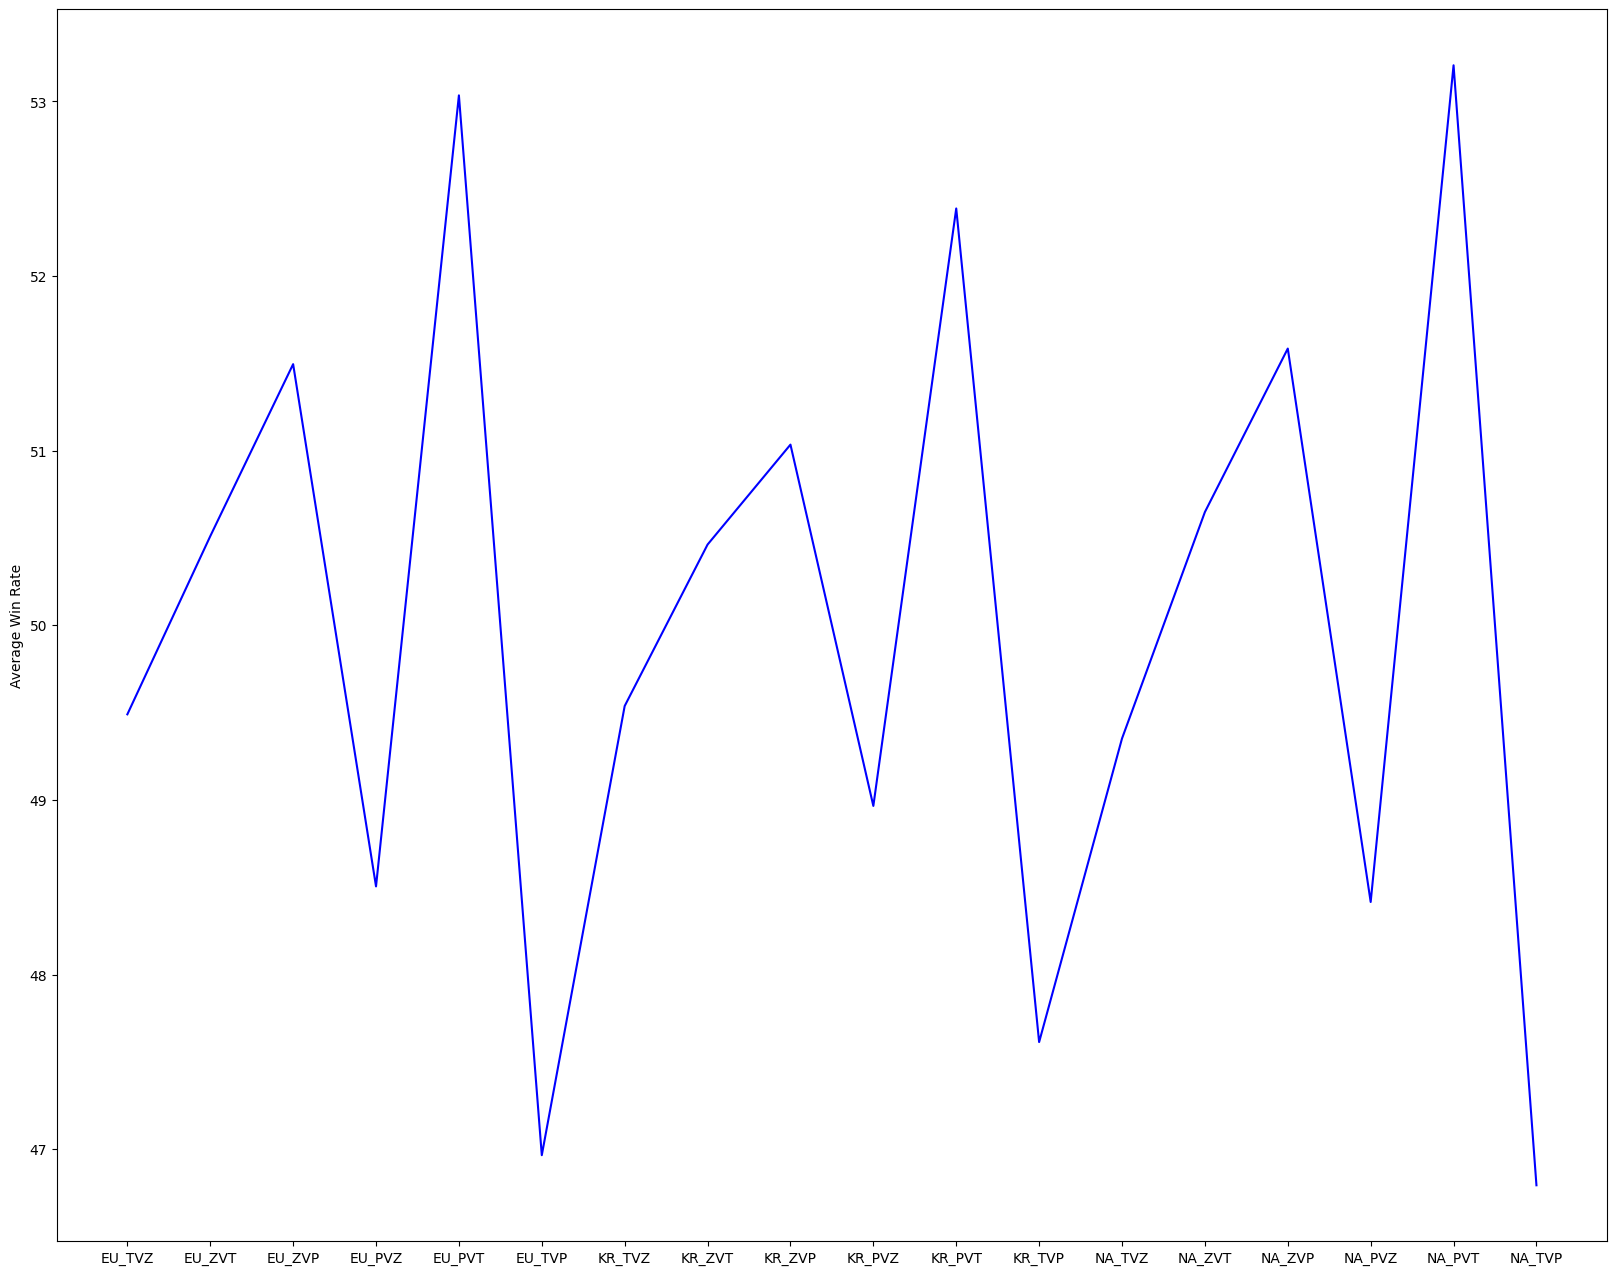

In [7]:
plt.figure(figsize=(20,16))
plt.ylabel("Average Win Rate")
plt.plot(WinRates.mean(), color="b")
plt.show()

This line plot shows the difference in average win rates better. We can see that the win rates fluctuate between ~47% to ~53%

<Axes: >

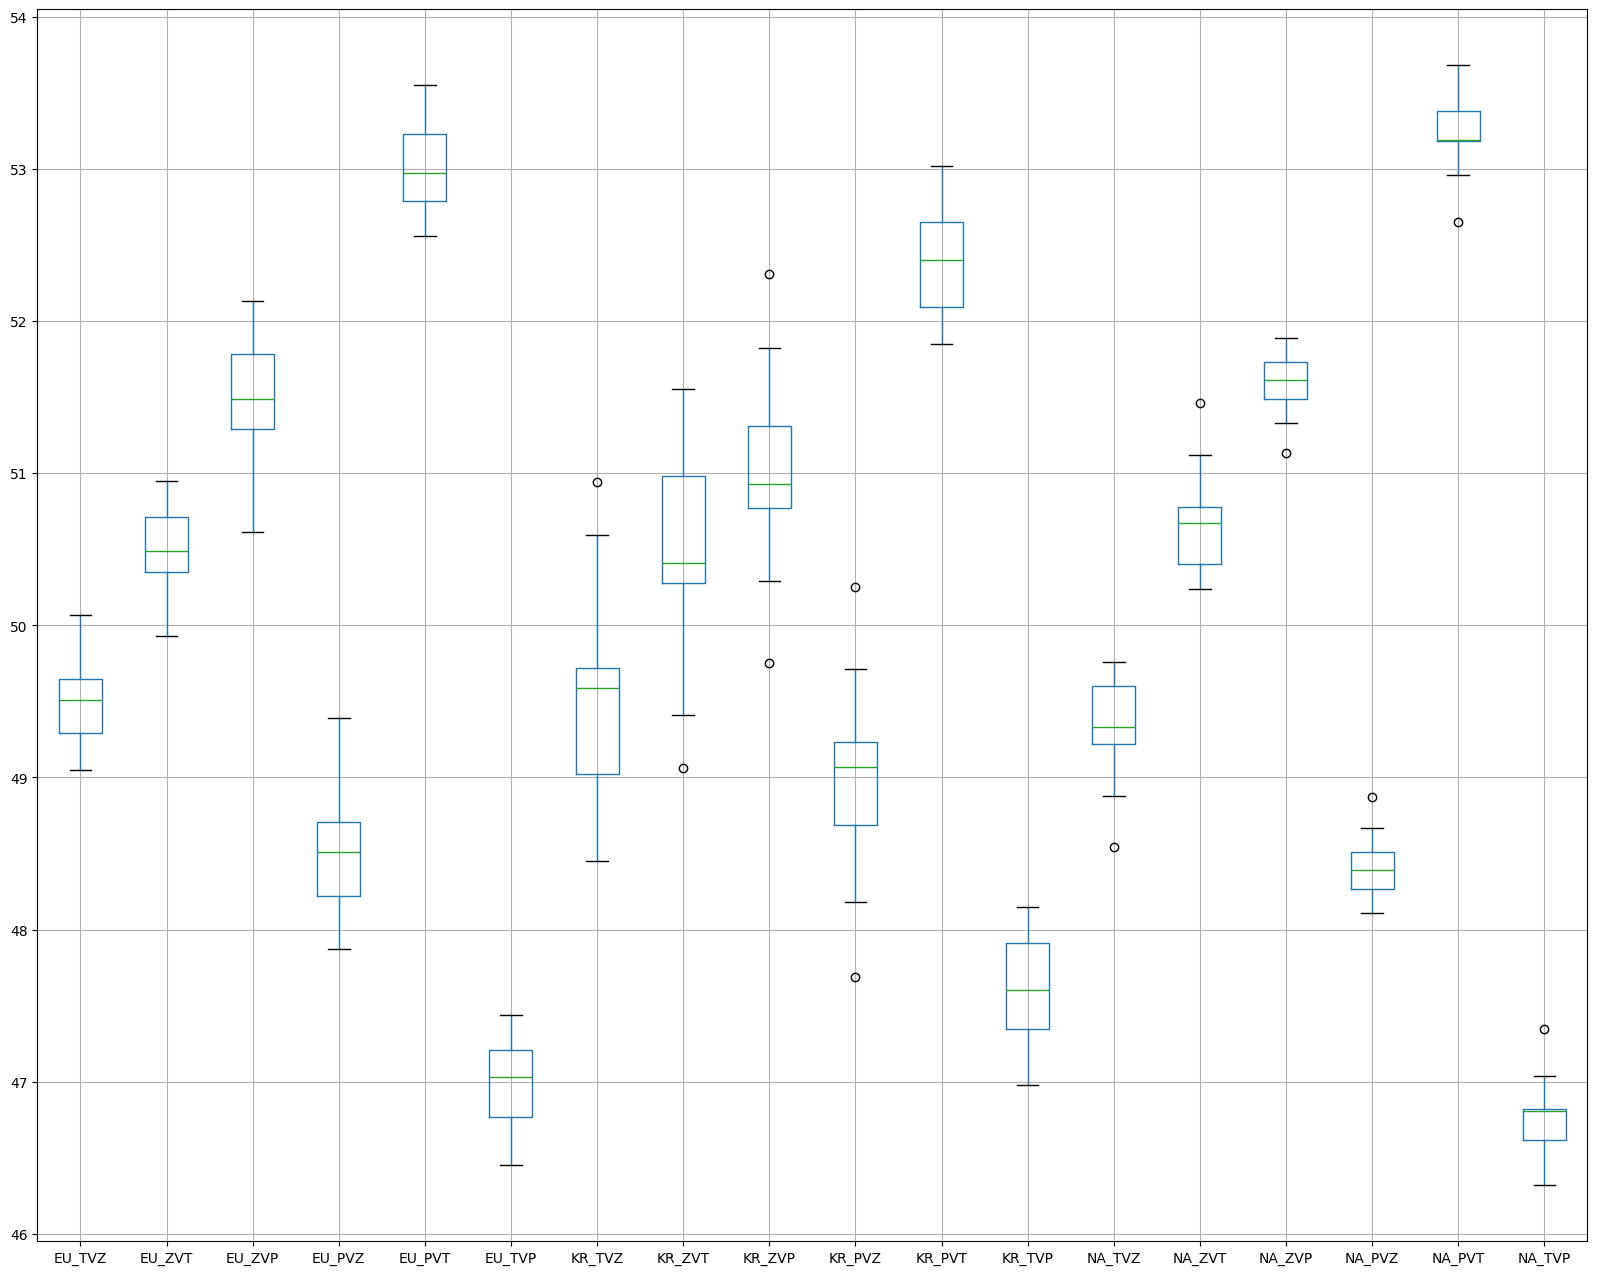

In [8]:
WinRates.boxplot(figsize=(20,16))

From this boxplot, I can see that that there is a lot of disparity between win rates. Both between averages and their ranges. For example, KR_TVZ has a large range of win rates when compared to NA_ZVP. I will do a describe to help see the ranges in numerical form.

In [9]:
WinRates.describe()

,EU_TVZ,EU_ZVT,EU_ZVP,EU_PVZ,EU_PVT,EU_TVP,KR_TVZ,KR_ZVT,KR_ZVP,KR_PVZ,KR_PVT,KR_TVP,NA_TVZ,NA_ZVT,NA_ZVP,NA_PVZ,NA_PVT,NA_TVP
count,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000,13.000000
mean,49.490000,50.510000,51.495385,48.504615,53.034615,46.965385,49.537692,50.462308,51.034615,48.965385,52.386923,47.613077,49.351538,50.648462,51.584615,48.415385,53.206923,46.793077
std,0.273374,0.273374,0.417625,0.417625,0.318450,0.318450,0.724237,0.724237,0.659123,0.659123,0.335370,0.335370,0.352629,0.352629,0.206221,0.206221,0.251409,0.251409
min,49.050000,49.930000,50.610000,47.870000,52.560000,46.450000,48.450000,49.060000,49.750000,47.690000,51.850000,46.980000,48.540000,50.240000,51.130000,48.110000,52.650000,46.320000
25%,49.290000,50.350000,51.290000,48.220000,52.790000,46.770000,49.020000,50.280000,50.770000,48.690000,52.090000,47.350000,49.220000,50.400000,51.490000,48.270000,53.180000,46.620000
50%,49.510000,50.490000,51.490000,48.510000,52.970000,47.030000,49.590000,50.410000,50.930000,49.070000,52.400000,47.600000,49.330000,50.670000,51.610000,48.390000,53.190000,46.810000
75%,49.650000,50.710000,51.780000,48.710000,53.230000,47.210000,49.720000,50.980000,51.310000,49.230000,52.650000,47.910000,49.600000,50.780000,51.730000,48.510000,53.380000,46.820000
max,50.070000,50.950000,52.130000,49.390000,53.550000,47.440000,50.940000,51.550000,52.310000,50.250000,53.020000,48.150000,49.760000,51.460000,51.890000,48.870000,53.680000,47.350000


For a start, we can see Korean Terran vs Zerg has the largest standard deviation between win rates, close to double of most and even triple of some of them. Another thing to note is the win rates for Terran vs Protoss across all regions as mentioned earlier. While being some of the lowest win rates, they dont deviate much from the average. This leads me to believe what I mentioned at the start about Terran vs Protoss at the lower levels where most players are at being true.

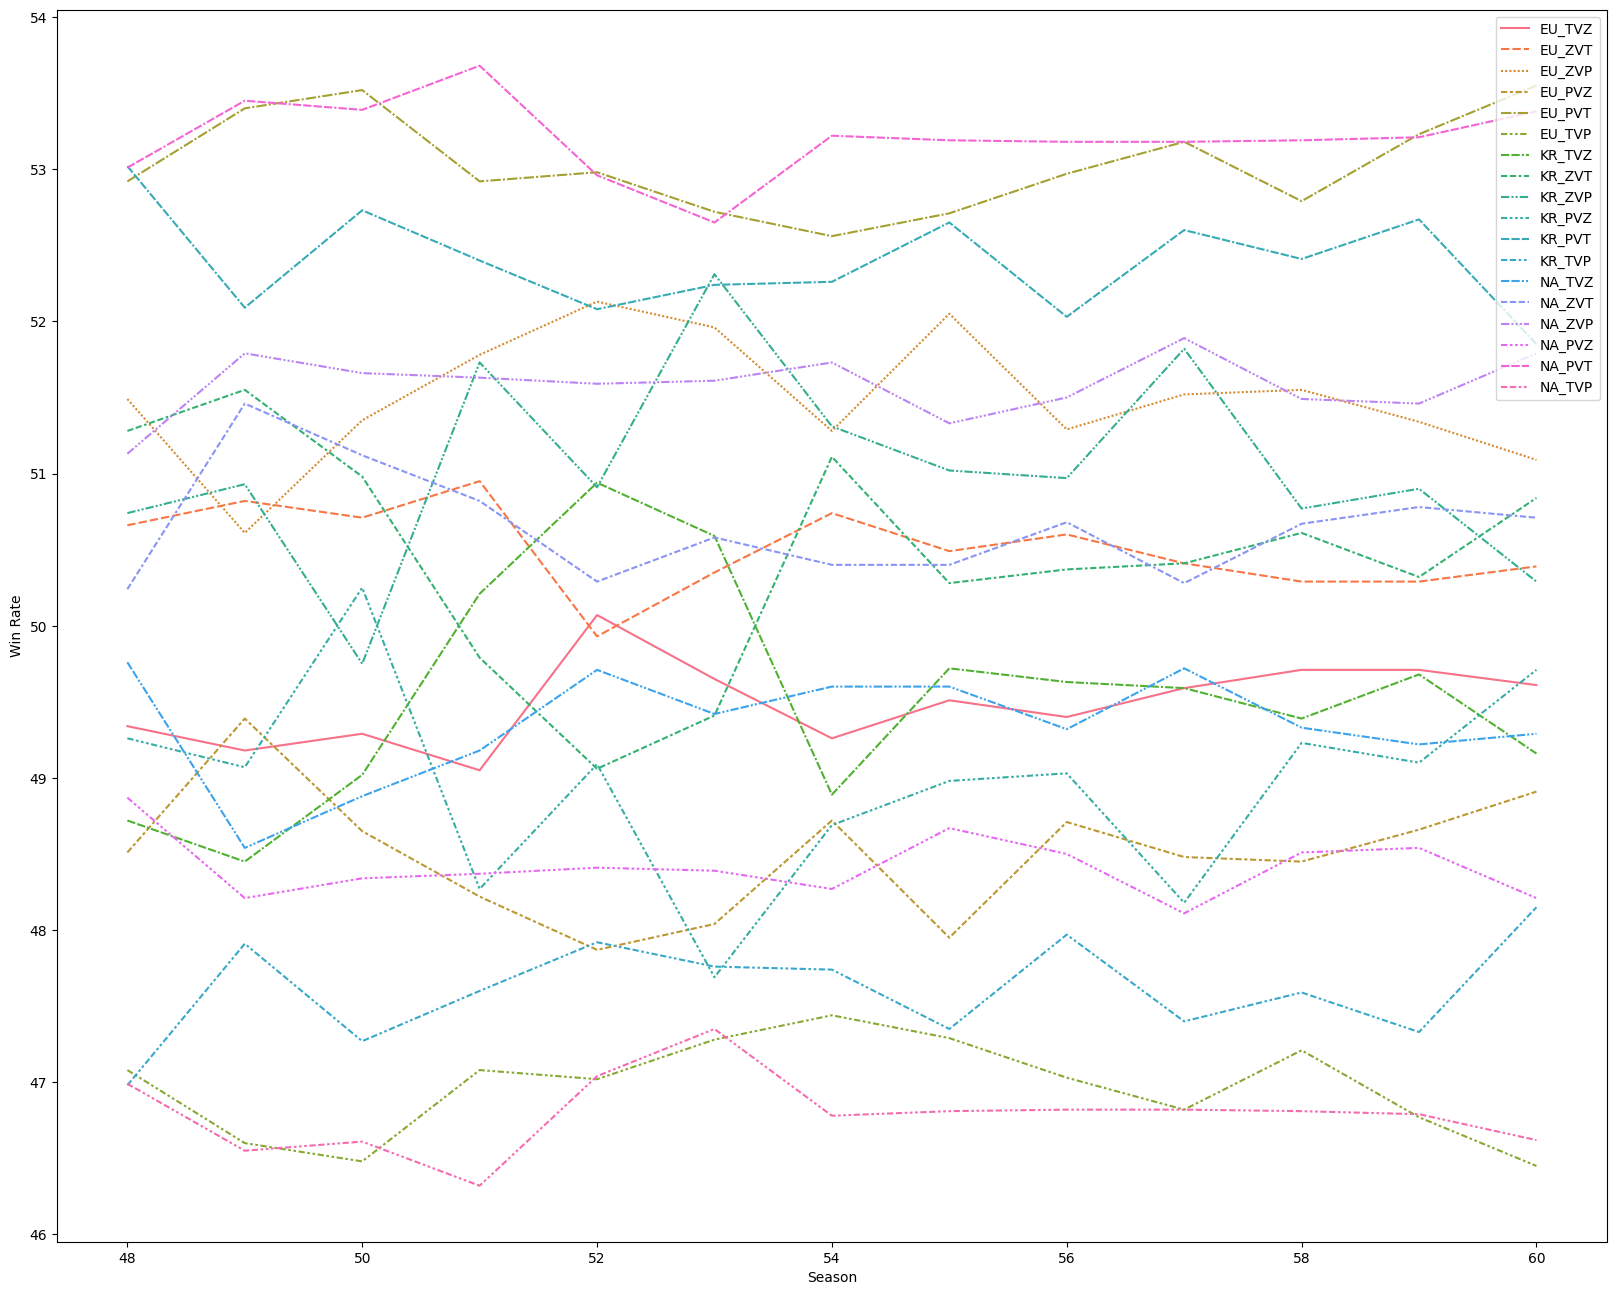

In [10]:
plt.figure(figsize=(20,16))
plt.xlabel("Season")
plt.ylabel("Win Rate")
sns.lineplot(data=WinRates)
plt.show()

The lineplot shows the change in win rates over the seasons. While most of the win rates generally dont fluctuate much, maybe around 1%. The biggest fluctuation noticeable is Korean Terran vs Zerg about 2%. There was a large rise from season 49 to 52 then back down again in 54. There was not much change in the game during that period of time 10 (November 2021 - 5 January 2023). I believe that gradual rise in win rate was due to player skill in general increasing. The StarCraft scene in Korea has been very popular since its launch in 1998 and they are known for being very skilled in general. Since there was little to no changes in this period, people eventually developed better tactics which gave them a better chance at winning the Terran vs Zerg matchup

### Conclusion and closing thoughts
After conducting some analysis on this simple dataset and making some observations. I feel that I can conclude on a surface level that the 3 races are not balanced for the general playerbase. There are nuances to this conclusion however, as the StarCraft games are very complex with many different possibilites and factors to take into consideration when looking into the balance between the 3 races. If i could I would have liked to be able to dive deeper into the individual stats that affect wether or not a player wins in a certain matchup but the amount of space and time needed to process the data is much too large a scope for this assignment.


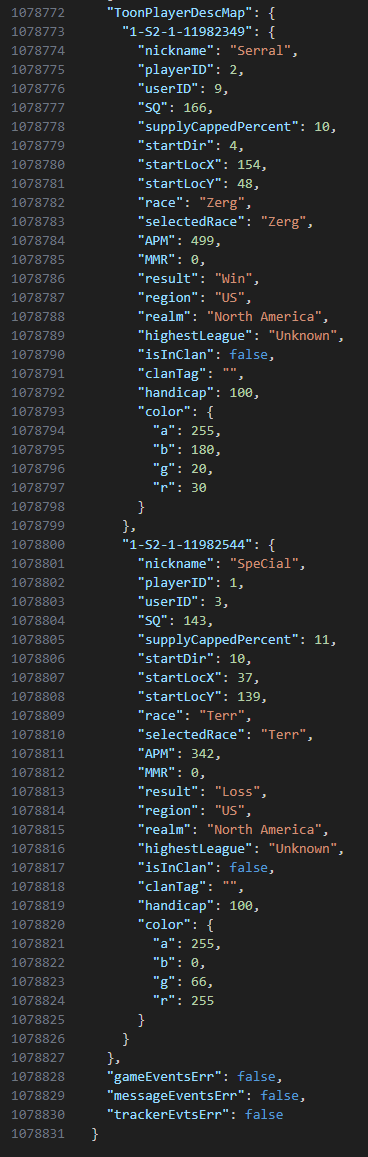

Here is a snippet from one singular replay data. As you can see there are over a million lines in this json file in total that documents each action these 2 professional players take in a single match.

And this is the size of just one match

Lastly, here is the size of the match replay data for this one tournament that has 261 matches.

Overall, I believe this study has helped to visualize people's concerns about game balance as a whole and not just at the professional level where most people watch

#### JULIAN: Provide a reference list

#### JULIAN: The above may be difficult to interpret!  Please consider this???

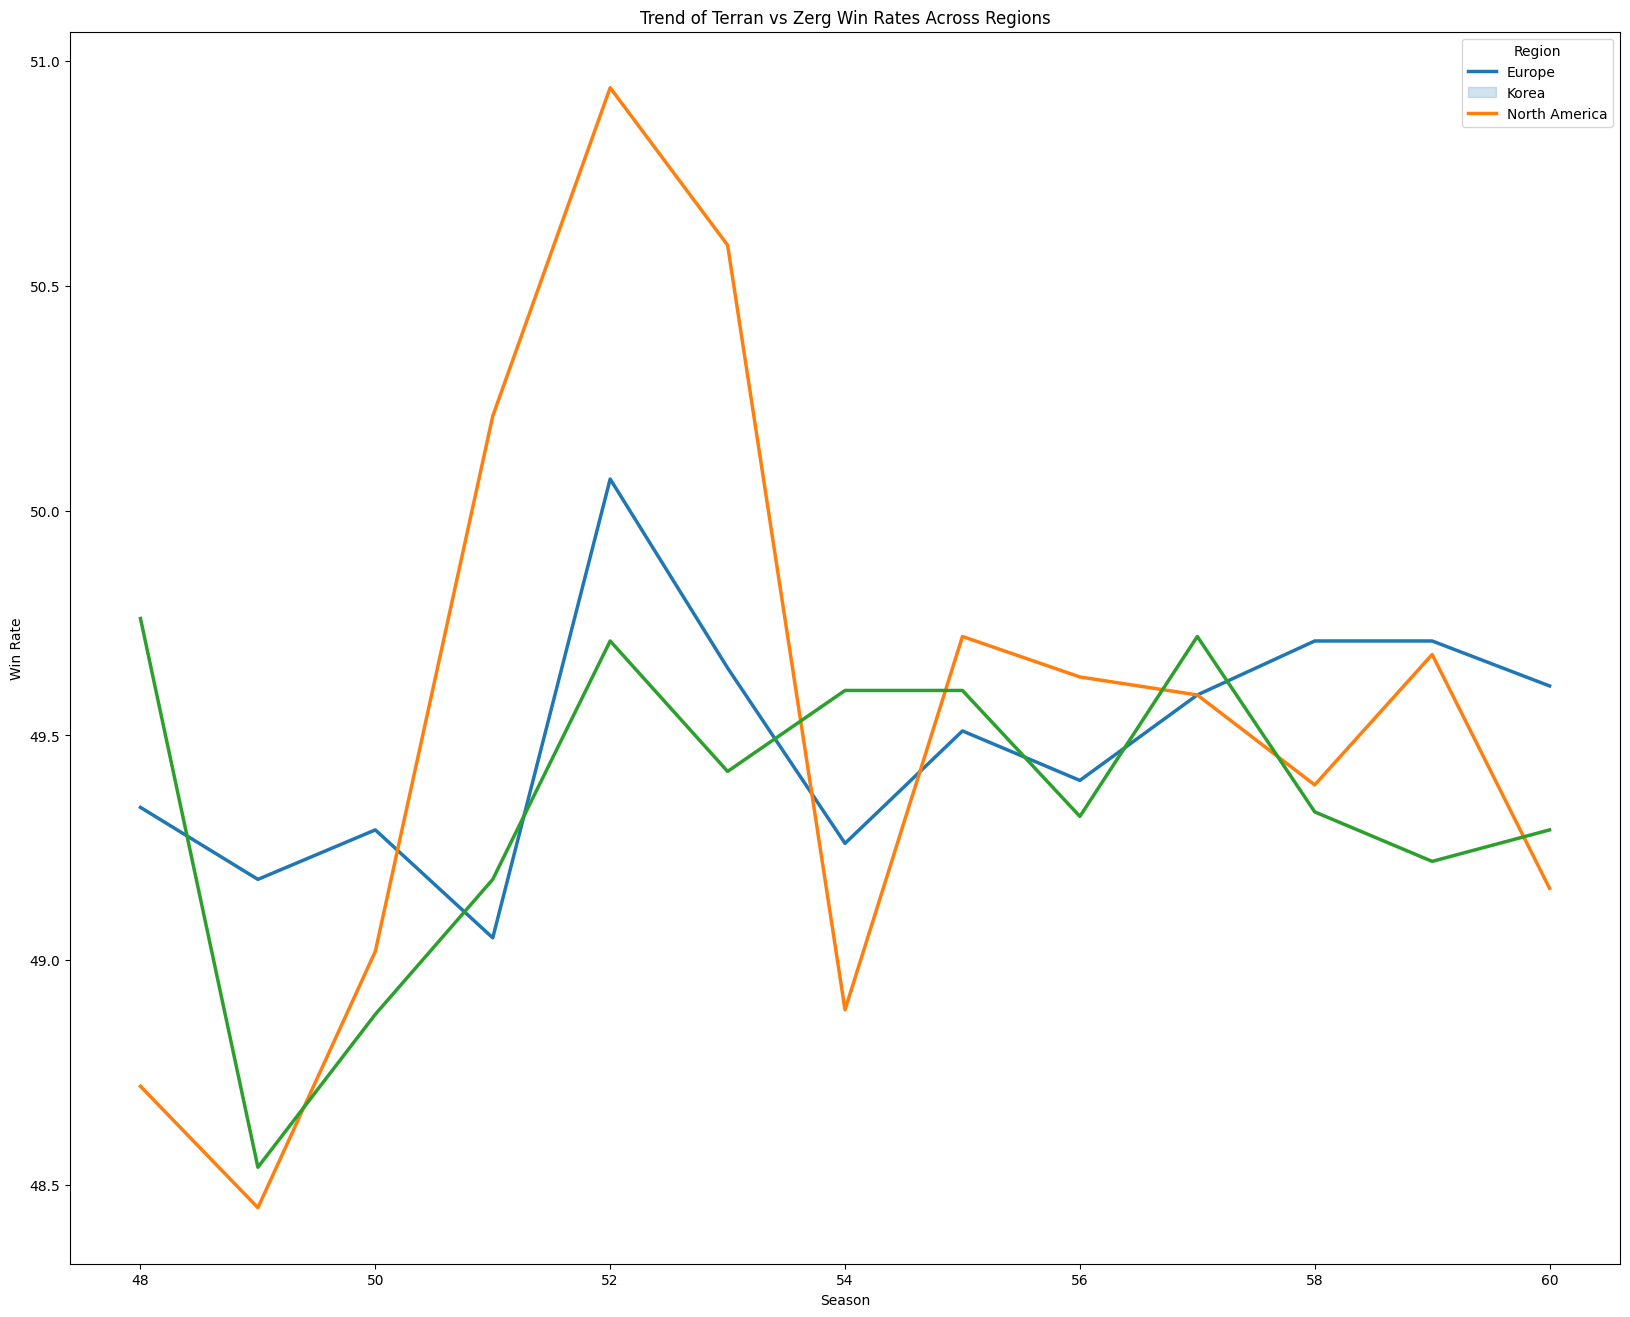

In [11]:
plt.figure(figsize=(20, 16))
plt.xlabel("Season")
plt.ylabel("Win Rate")

# Plot only a few key matchups for clarity
sns.lineplot(data=WinRates[['EU_TVZ', 'KR_TVZ', 'NA_TVZ']], dashes=False, 
             palette='tab10', linewidth=2.5)
plt.title('Trend of Terran vs Zerg Win Rates Across Regions')
plt.legend(title='Region', labels=['Europe', 'Korea', 'North America'])
plt.show()

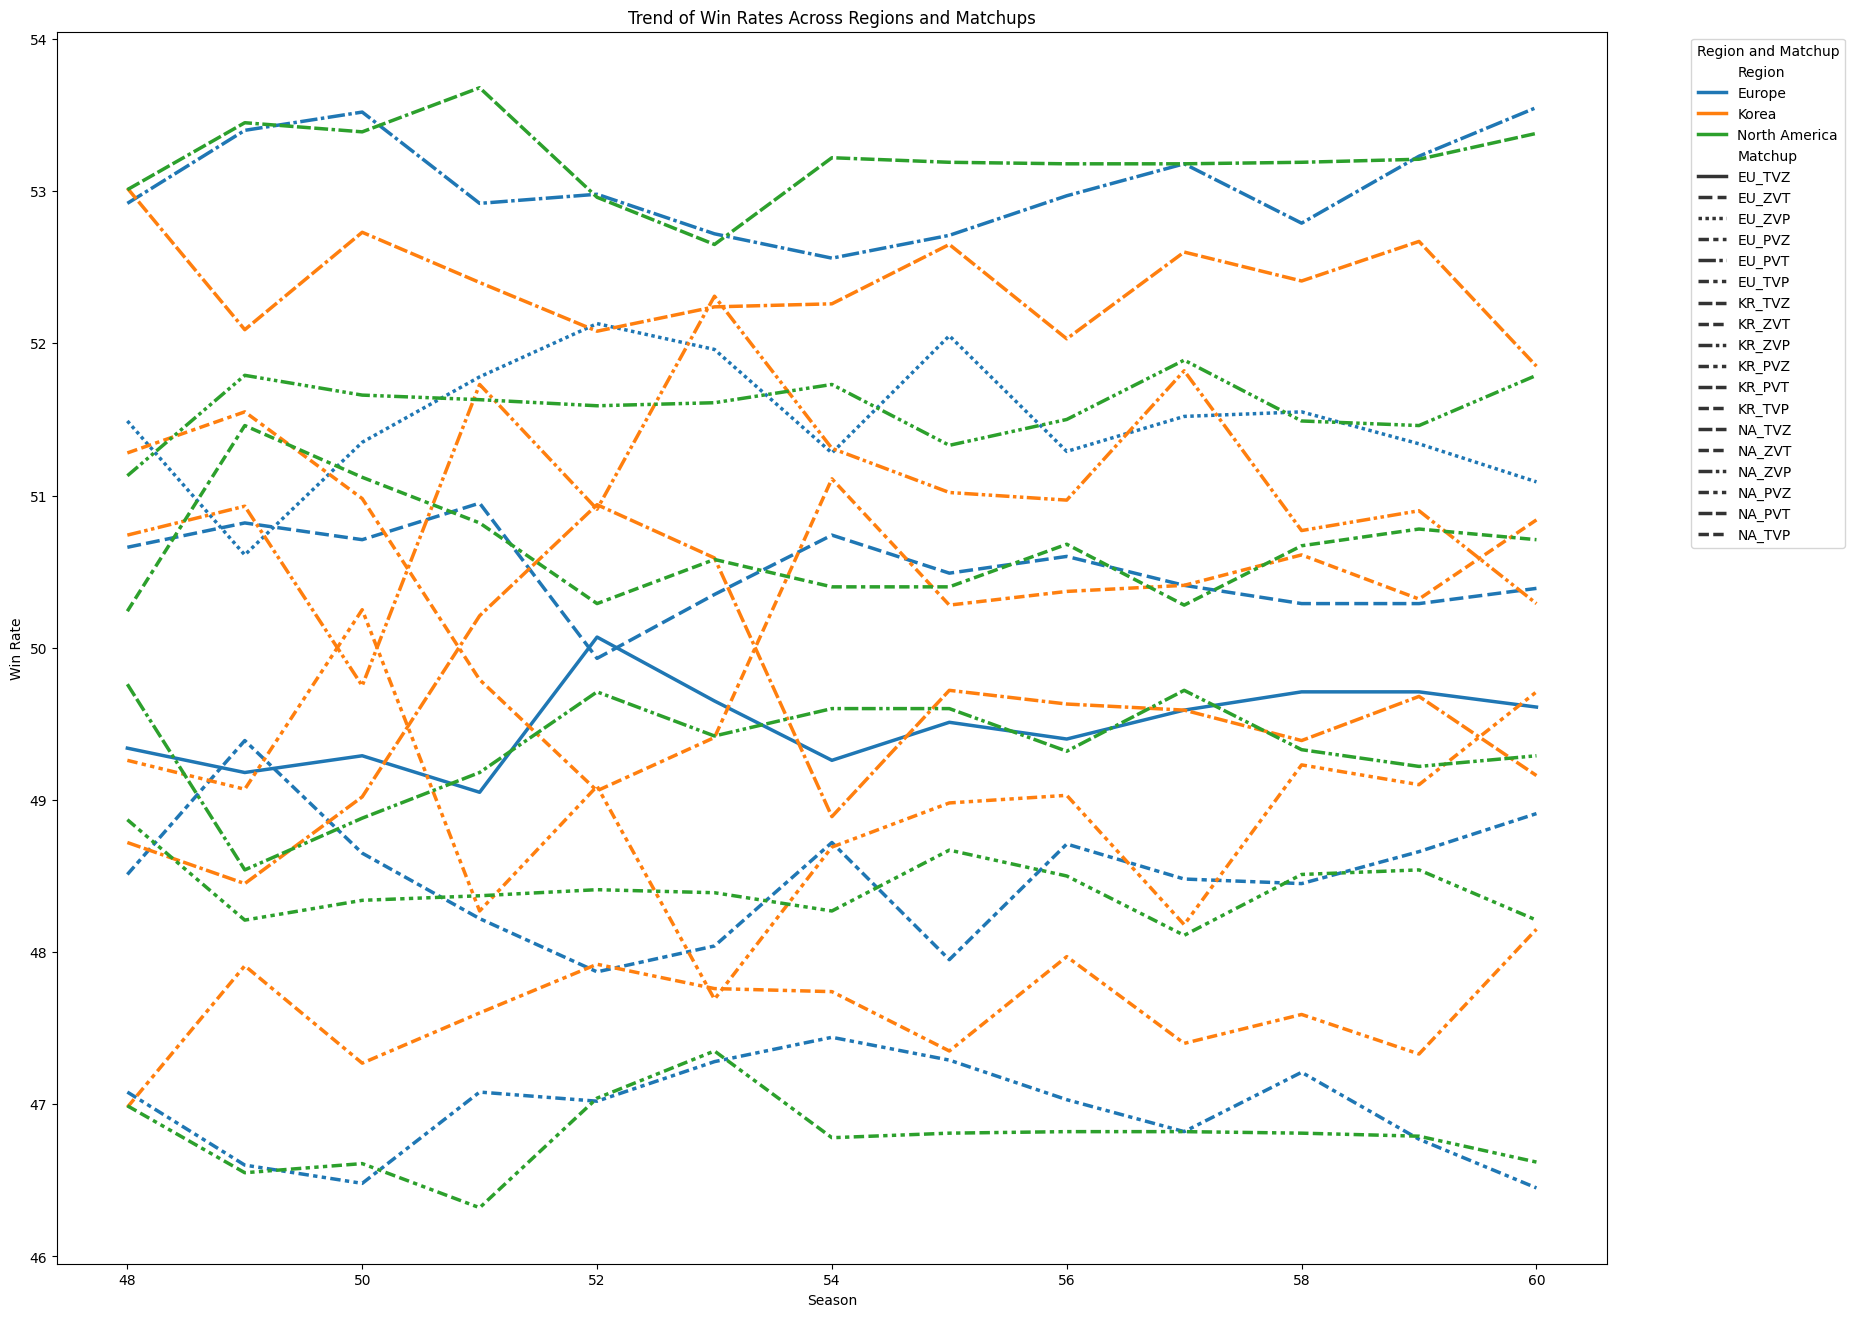

In [12]:
# Melt the dataframe to long format for easier plotting
WinRates_long = WinRates.melt(ignore_index=False, var_name='Matchup', value_name='Win Rate')

# Add a 'Region' column based on the matchup prefix
WinRates_long['Region'] = WinRates_long['Matchup'].str[:2].replace({
    'EU': 'Europe', 'KR': 'Korea', 'NA': 'North America'
})

# Plot
plt.figure(figsize=(20, 16))
sns.lineplot(data=WinRates_long, x=WinRates_long.index, y='Win Rate', hue='Region', style='Matchup', 
             palette='tab10', linewidth=2.5)
plt.title('Trend of Win Rates Across Regions and Matchups')
plt.xlabel('Season')
plt.ylabel('Win Rate')
plt.legend(title='Region and Matchup', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

#### JULIAN: You may consider other plot? Please see revise and explain if these give you some more ideas

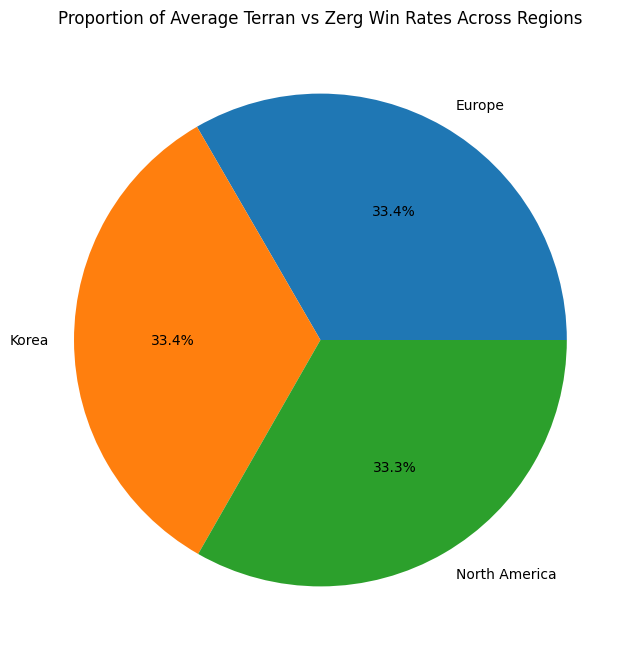

In [13]:
plt.figure(figsize=(8, 8))
WinRates[['EU_TVZ', 'KR_TVZ', 'NA_TVZ']].mean().plot(kind='pie', autopct='%1.1f%%', 
                                                      labels=['Europe', 'Korea', 'North America'])
plt.title('Proportion of Average Terran vs Zerg Win Rates Across Regions')
plt.show()

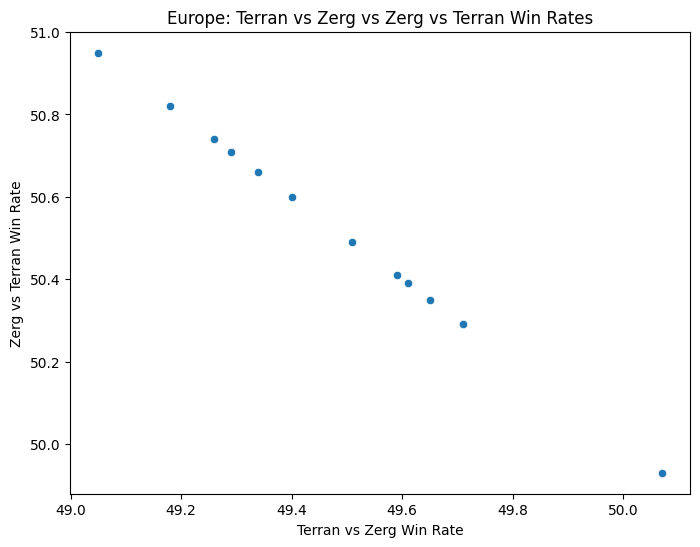

In [14]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=WinRates['EU_TVZ'], y=WinRates['EU_ZVT'])
plt.title('Europe: Terran vs Zerg vs Zerg vs Terran Win Rates')
plt.xlabel('Terran vs Zerg Win Rate')
plt.ylabel('Zerg vs Terran Win Rate')
plt.show()

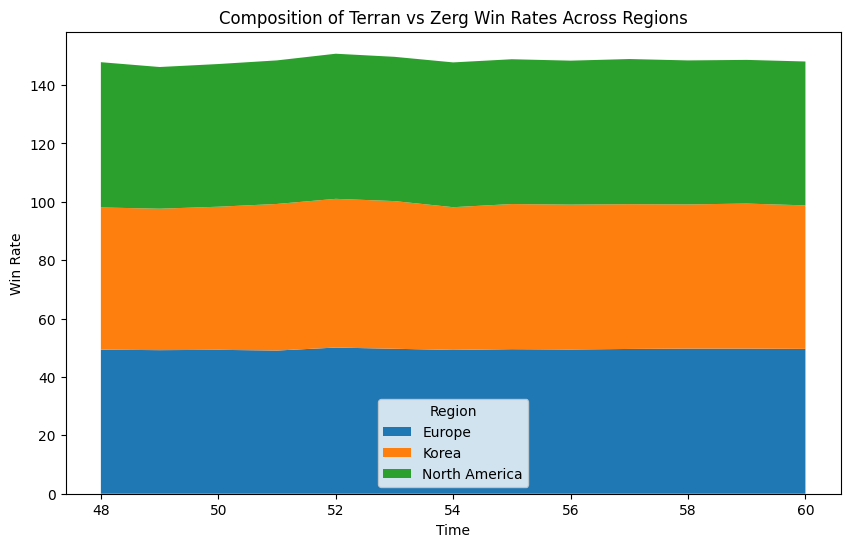

In [15]:
plt.figure(figsize=(10, 6))
plt.stackplot(WinRates.index, WinRates['EU_TVZ'], WinRates['KR_TVZ'], WinRates['NA_TVZ'], 
              labels=['Europe', 'Korea', 'North America'])
plt.title('Composition of Terran vs Zerg Win Rates Across Regions')
plt.xlabel('Time')
plt.ylabel('Win Rate')
plt.legend(title='Region')
plt.show()

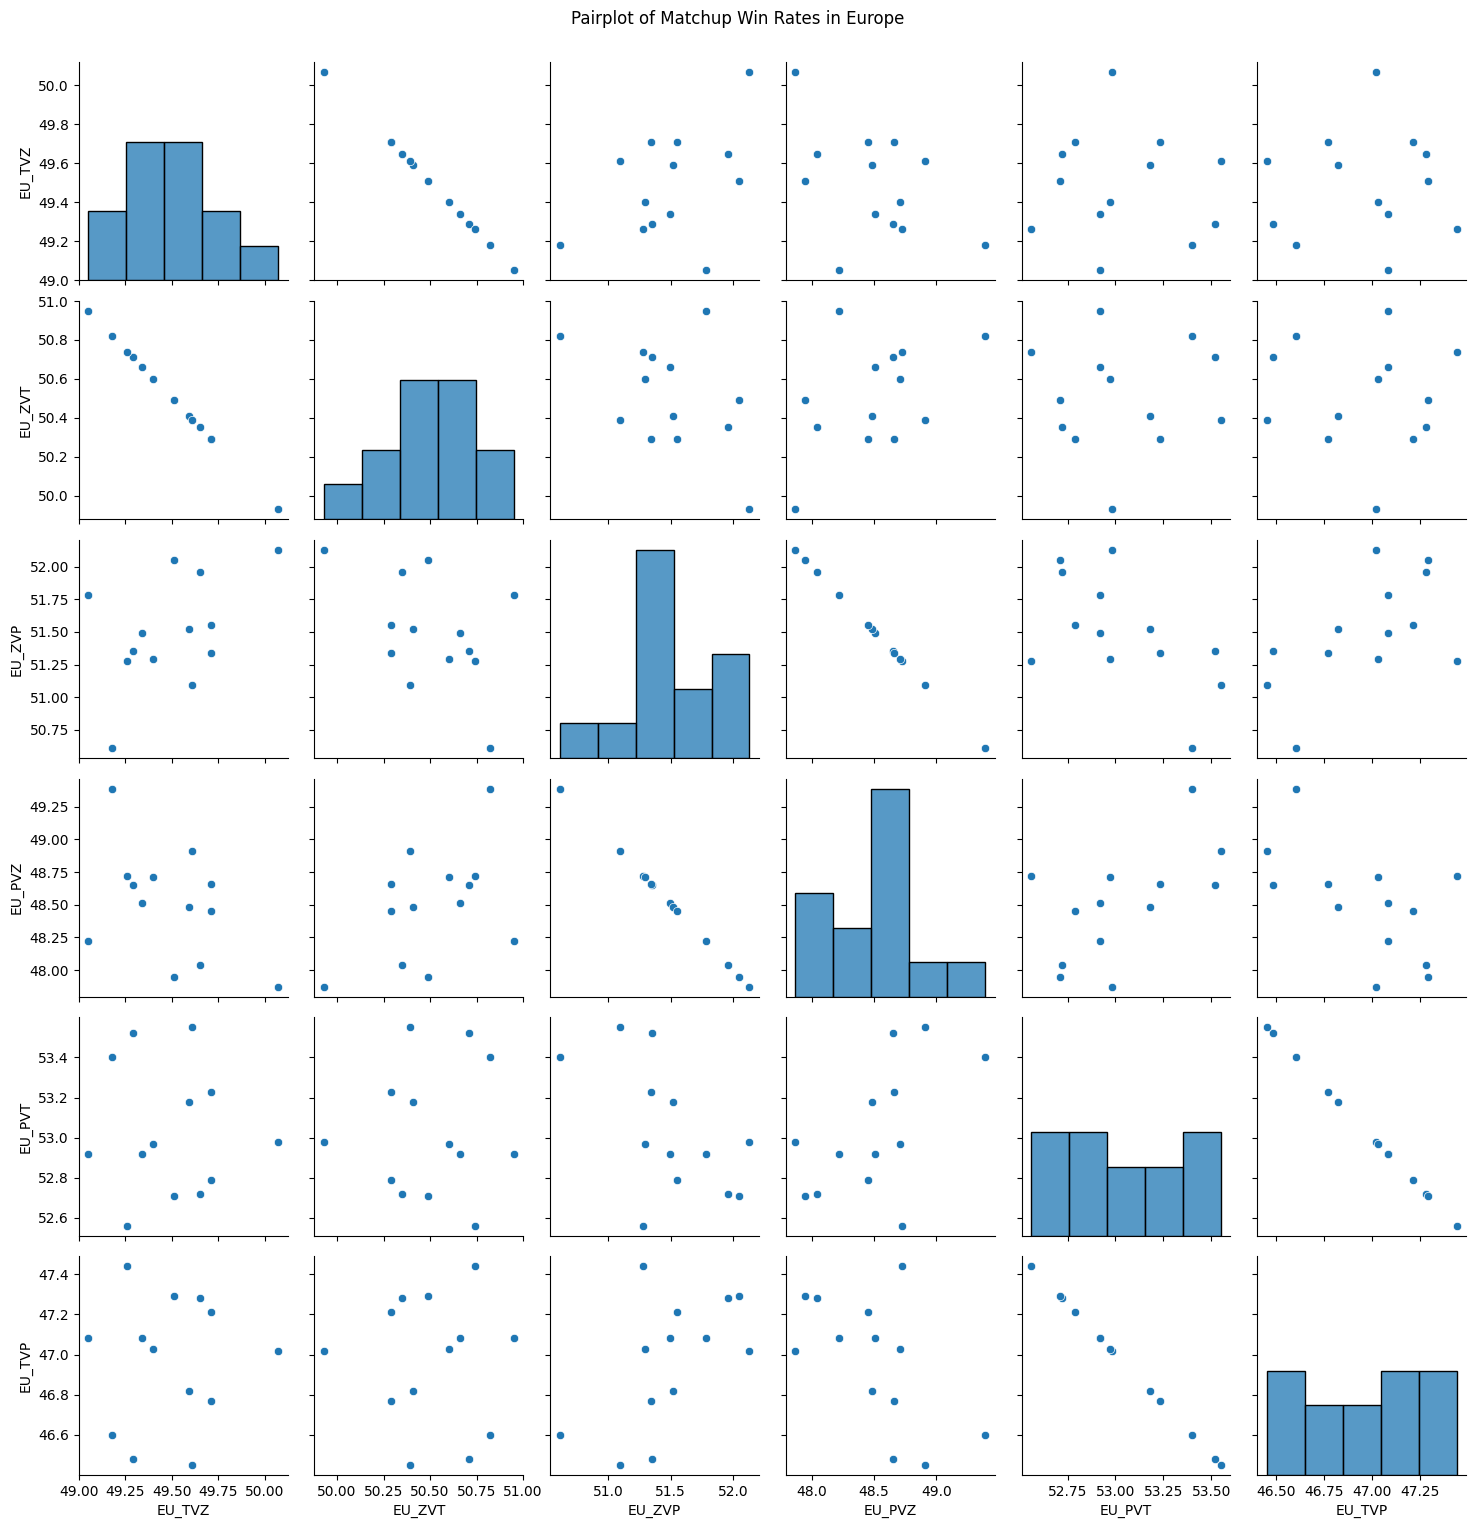

In [16]:
sns.pairplot(WinRates[['EU_TVZ', 'EU_ZVT', 'EU_ZVP', 'EU_PVZ', 'EU_PVT', 'EU_TVP']])
plt.suptitle('Pairplot of Matchup Win Rates in Europe', y=1.02)
plt.show()

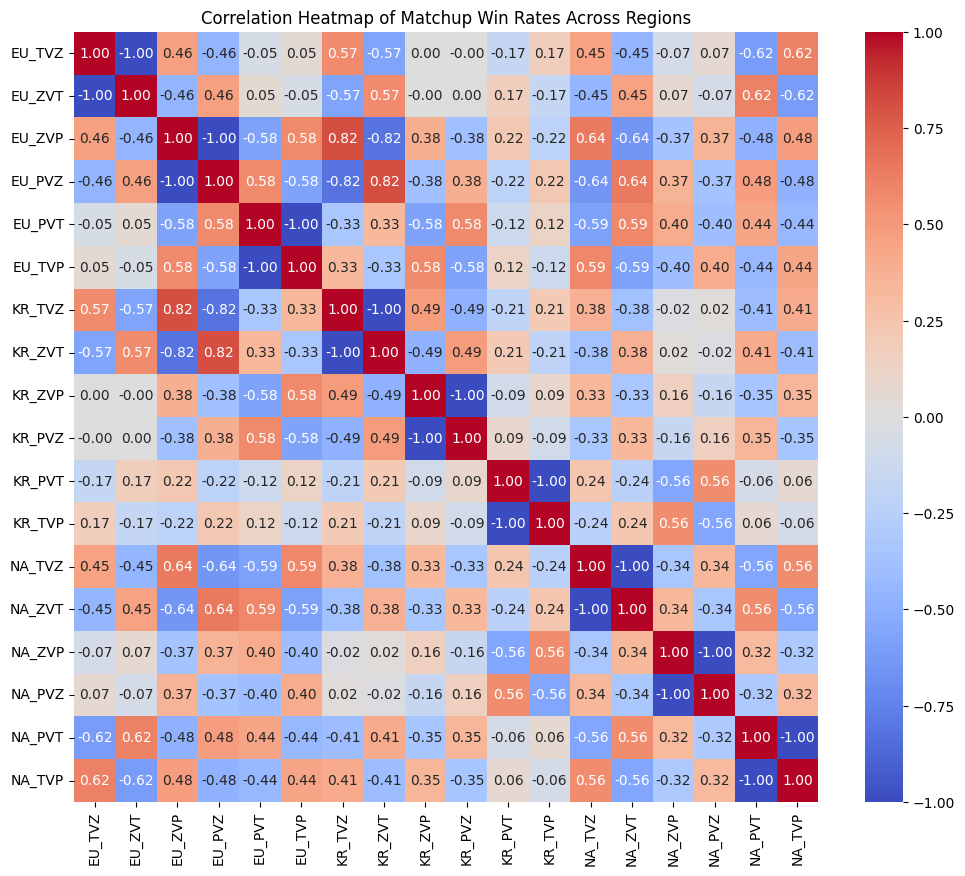

In [17]:
plt.figure(figsize=(12, 10))
sns.heatmap(WinRates.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Matchup Win Rates Across Regions')
plt.show()

#### JULIAN:

Overall comments:

Your report about race balance in StarCraft 2 shows good coding skills, using web scraping to get data from nonapa.com, which uses Blizzard's official API. This ensures the data is valid and relevant. Your visualizations, like line plots and boxplots, highlight key trends and differences in win rates, such as Terrans' lower win rates against Protoss and the variability in Korean Terran vs. Zerg matchups. These results communicate a narrative that fits well with the discussion on game balance in the StarCraft 2 community. The data processing pipeline is fine, from scraping and organizing the data into a pandas DataFrame to saving it as a CSV file. Using libraries like NumPy, pandas, and Seaborn shows a solid grasp of the necessary tools for data analysis.  You also draw meaningful conclusions from the data, such as the impact of unit design and player skill on win rates. Overall, your report shows a good effort that lays a strong foundation for further exploration and improvement.

There are several areas where you can improve to meet the criteria better. My suggestion below is based on what is listed in the rubric. I have identified a few areas that are missing or do not fulfill the rubric. First, although you have outlined the scope of your work, there’s no explicit mention of **exclusion and inclusion criteria** for the data. For example, why were only seasons 48 to 60 chosen (we discussed this so many times in our classess and it is also part of the rubric), and not earlier seasons? Were certain regions or skill levels excluded? Defining these criteria would clarify the boundaries of your analysis and ensure transparency in your methodology.  Second, your analysis does not include **checks for out-of-bound values** or validation of numeric and categorical quantities. For instance, win rates should logically fall between 0% and 100%, but there’s no verification of this. Additionally, sorting data into logical groups (e.g., top 10%, bottom 10%) or identifying anomalies (e.g., extreme outliers) would strengthen the reliability of your findings. These steps are crucial as these are highlighted in the rubric. Third, although the justification on  the use of the nonapa.com dataset is given, no **consideration of at least two other datasets** and their potential strengths and weaknesses. This is also part of the requirements in the rubric.

Fourth, your analysis does not explicitly address **potential biases in the dataset**. For instance, the dataset might overrepresent certain regions (e.g., Korea) or skill levels, which could skew the results. A discussion of these biases and their potential impact on your conclusions would make your analysis more robust and nuanced. Fifth, while your EDA includes visualizations like line plots and boxplots, there’s limited **depth in exploration**. For example, you could have analyzed trends over time more granularly (e.g., by splitting the data into skill tiers or regions) or identified specific seasons where imbalances were most pronounced. I have provided you with some examples to consider. A discussion of **why this topic has not been previously explored** or how your research questions differ from existing studies is also part of the requirements in the rubric, please address this as it is important to highlight the novelty of your work and its contribution to the field of game balance analysis. Overall, you need to strengthen your writing and add more detailed content, as mentioned in the rubric.


Last but not least, please ensure that you have "re-verified" all the grading criteria in the rubric. Reviewing the recent webinar recording posted by Sean can provide additional insights and help you address any remaining gaps in your work.

I understand it may feel overwhelming with so much to focus on. Please do your best, and if you are short on time, just try to revise and submit what you have.

I hope this is useful.

All the best for the submission!

Sincerely, Julian